# Digital Advertising Budget Optimizer
**Big Data Analytics Project** | Name: _laiba__ | Roll No: ___502_____

**Problem:** Company Facebook, Instagram, Google, TikTok aur YouTube par ads chalati hai. Management ka sawal: *agla Rs. 1 million kahan lagayein?*

**Is notebook mein:** simulated data (10K, 100K, 1M, 10M) -> metrics -> Pandas vs MapReduce vs Spark comparison -> Budget Recommendation Engine -> charts.

## Step 1: Libraries aur Settings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time, os, sys, csv
from collections import defaultdict

np.random.seed(42)
os.makedirs("data", exist_ok=True)

# Agar 10M ka test skip karna ho to False kar do
RUN_10M = True

## Step 2: Data Generator (simulated ad data, 12 columns)

In [2]:
platforms = ["Facebook", "Instagram", "Google", "TikTok", "YouTube"]

# Har platform ki "personality": cpm = 1000 impressions ki cost, ctr = click rate,
# cvr = click ke baad khareedne ka rate, aov = average order value (Rs.)
platform_settings = {
    "Facebook":  {"cpm": 250, "ctr": 0.012, "cvr": 0.040, "aov": 3500},
    "Instagram": {"cpm": 300, "ctr": 0.015, "cvr": 0.035, "aov": 3800},
    "Google":    {"cpm": 450, "ctr": 0.030, "cvr": 0.060, "aov": 4200},
    "TikTok":    {"cpm": 150, "ctr": 0.020, "cvr": 0.015, "aov": 2800},
    "YouTube":   {"cpm": 200, "ctr": 0.008, "cvr": 0.025, "aov": 3200},
}

def generate_data(n_rows):
    # Drama campaigns: YouTube par sab se zyada
    platform = np.random.choice(platforms, n_rows, p=[0.20, 0.15, 0.10, 0.15, 0.40])

    cpm = np.array([platform_settings[p]["cpm"] for p in platform])
    ctr = np.array([platform_settings[p]["ctr"] for p in platform])
    cvr = np.array([platform_settings[p]["cvr"] for p in platform])
    aov = np.array([platform_settings[p]["aov"] for p in platform])

    impressions = np.random.randint(1000, 50000, n_rows)
    clicks = np.random.binomial(impressions, ctr)
    conversions = np.random.binomial(clicks, cvr)

    spend = (impressions / 1000) * cpm * np.random.uniform(0.8, 1.2, n_rows)
    revenue = conversions * aov * np.random.uniform(0.8, 1.2, n_rows)

    return pd.DataFrame({
        "date": pd.to_datetime("2025-01-01") + pd.to_timedelta(np.random.randint(0, 365, n_rows), unit="D"),
        "campaign": np.random.choice(["Mere Humsafar", "Tere Bin", "Kabhi Main Kabhi Tum", "Sunn Mere Dil", "Ishq Murshid"], n_rows),
        "platform": platform,
        "impressions": impressions,
        "clicks": clicks,
        "spend": spend.round(2),
        "conversions": conversions,
        "revenue": revenue.round(2),
        "age": np.random.randint(18, 56, n_rows),
        "gender": np.random.choice(["Male", "Female"], n_rows),
        "city": np.random.choice(["Lahore", "Karachi", "Islamabad", "Faisalabad", "Multan", "Peshawar"], n_rows),
        "device": np.random.choice(["Mobile", "Desktop", "Tablet"], n_rows, p=[0.7, 0.2, 0.1]),
    })

generate_data(5)

,date,campaign,platform,impressions,clicks,spend,conversions,revenue,age,gender,city,device
0,2025-09-21,Sunn Mere Dil,Google,17850,515,8611.83,27,108202.49,35,Female,Peshawar,Mobile
1,2025-02-04,Tere Bin,YouTube,38194,284,7487.55,6,15482.62,43,Male,Faisalabad,Mobile
2,2025-07-25,Tere Bin,YouTube,22962,208,3698.29,10,28555.44,51,Female,Lahore,Desktop
3,2025-03-22,Sunn Mere Dil,TikTok,48191,932,8507.26,14,35139.28,27,Male,Peshawar,Mobile
4,2025-02-19,Ishq Murshid,Facebook,45131,565,11568.38,28,105183.93,53,Female,Multan,Mobile


## Step 3: Datasets (10K, 100K, 1M)

In [3]:
df_10k = generate_data(10_000)
df_100k = generate_data(100_000)
df_1m = generate_data(1_000_000)

df_10k.to_csv("data/ads_10k.csv", index=False)
df_100k.to_csv("data/ads_100k.csv", index=False)
df_1m.to_csv("data/ads_1m.csv", index=False)

print("Shapes:", df_10k.shape, df_100k.shape, df_1m.shape)

Shapes: (10000, 12) (100000, 12) (1000000, 12)


### 10M records (chunks mein, taake 8 GB RAM full na ho)
Agar `data/ads_10m.csv` pehle se bani hui hai to dobara nahi banegi.

In [4]:
path_10m = "data/ads_10m.csv"

if RUN_10M and not os.path.exists(path_10m):
    t = time.time()
    for i in range(10):
        chunk = generate_data(1_000_000)
        chunk.to_csv(path_10m, mode="w" if i == 0 else "a", header=(i == 0), index=False)
        del chunk
        print("chunk", i + 1, "done")
    print("10M saved in", round(time.time() - t, 1), "sec")
elif os.path.exists(path_10m):
    print("10M file already exists, skipping")
else:
    print("10M skipped (RUN_10M = False)")

chunk 1 done
chunk 2 done
chunk 3 done
chunk 4 done
chunk 5 done
chunk 6 done
chunk 7 done
chunk 8 done
chunk 9 done
chunk 10 done
10M saved in 140.2 sec


## Step 4: Metrics (CTR, CPC, CPA, Conversion Rate, ROAS)

In [5]:
def add_metrics(df):
    df = df.copy()
    df["ctr"] = df["clicks"] / df["impressions"]
    df["cpc"] = df["spend"] / df["clicks"].replace(0, np.nan)
    df["cpa"] = df["spend"] / df["conversions"].replace(0, np.nan)
    df["conversion_rate"] = df["conversions"] / df["clicks"].replace(0, np.nan)
    df["roas"] = df["revenue"] / df["spend"]
    return df

add_metrics(df_10k).head()

,date,campaign,platform,impressions,clicks,spend,conversions,revenue,age,gender,city,device,ctr,cpc,cpa,conversion_rate,roas
0,2025-08-25,Sunn Mere Dil,TikTok,27252,563,4404.48,11,32540.36,45,Male,Lahore,Mobile,0.020659,7.823233,400.407273,0.019538,7.388014
1,2025-02-28,Ishq Murshid,Facebook,10487,124,2507.09,8,27691.64,34,Male,Multan,Mobile,0.011824,20.218468,313.386250,0.064516,11.045331
2,2025-10-01,Tere Bin,YouTube,48829,351,8085.97,10,34769.92,51,Male,Multan,Mobile,0.007188,23.036952,808.597000,0.028490,4.300031
3,2025-09-20,Sunn Mere Dil,Facebook,41403,502,8845.54,18,73068.89,41,Female,Islamabad,Desktop,0.012125,17.620598,491.418889,0.035857,8.260535
4,2025-07-08,Kabhi Main Kabhi Tum,YouTube,15604,126,3242.03,3,7876.04,19,Male,Peshawar,Mobile,0.008075,25.730397,1080.676667,0.023810,2.429354


In [6]:
# Platform-wise summary (1M records)
df_1m_m = add_metrics(df_1m)

summary = df_1m_m.groupby("platform").agg(
    spend=("spend", "sum"),
    revenue=("revenue", "sum"),
    clicks=("clicks", "sum"),
    impressions=("impressions", "sum"),
    conversions=("conversions", "sum"),
)
summary["CTR"] = summary["clicks"] / summary["impressions"]
summary["CPC"] = summary["spend"] / summary["clicks"]
summary["CPA"] = summary["spend"] / summary["conversions"]
summary["ROAS"] = summary["revenue"] / summary["spend"]
summary.round(3)

,spend,revenue,clicks,impressions,conversions,CTR,CPC,CPA,ROAS
platform,,,,,,,,,
Facebook,1.274476e+09,8.565037e+09,61183832,5098654742,2446934,0.012,20.830,520.846,6.720
Google,1.144265e+09,1.924318e+10,76333860,2544403349,4579313,0.030,14.990,249.877,16.817
Instagram,1.151877e+09,7.656791e+09,57622997,3841158466,2014562,0.015,19.990,571.775,6.647
TikTok,5.752504e+08,3.224342e+09,76697968,3834832958,1152094,0.020,7.500,499.309,5.605
YouTube,2.034384e+09,6.506840e+09,81372459,10172002446,2033032,0.008,25.001,1000.665,3.198


## Step 5: Pandas vs MapReduce vs Spark

### 5a: Pandas aur MapReduce (Python map/reduce functions)

In [7]:
def run_pandas(path):
    t = time.time()
    df = pd.read_csv(path)
    res = df.groupby("platform")[["spend", "revenue"]].sum()
    return time.time() - t, res

def mapper(row):
    # har row -> (platform, (spend, revenue))
    return (row["platform"], (float(row["spend"]), float(row["revenue"])))

def reducer(mapped):
    # same platform ki values jama karo
    totals = defaultdict(lambda: [0.0, 0.0])
    for key, (s, r) in mapped:
        totals[key][0] += s
        totals[key][1] += r
    return dict(totals)

def run_mapreduce(path):
    t = time.time()
    with open(path, newline="") as f:
        mapped = map(mapper, csv.DictReader(f))   # MAP
        res = reducer(mapped)                     # REDUCE
    return time.time() - t, res

print("Pandas 10K:", round(run_pandas("data/ads_10k.csv")[0], 3), "sec")
print("MapReduce 10K:", round(run_mapreduce("data/ads_10k.csv")[0], 3), "sec")

Pandas 10K: 0.043 sec
MapReduce 10K: 0.078 sec


### 5b: Spark start

In [8]:
os.makedirs("spark_temp", exist_ok=True)
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession

t = time.time()
spark = (SparkSession.builder
         .appName("ads")
         .master("local[*]")
         .config("spark.driver.host", "127.0.0.1")
         .config("spark.driver.bindAddress", "127.0.0.1")
         .config("spark.local.dir", os.path.abspath("spark_temp"))
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())
print("Spark startup:", round(time.time() - t, 2), "sec")

def run_spark(path):
    t = time.time()
    df = spark.read.csv(path, header=True, inferSchema=True)
    res = df.groupBy("platform").sum("spend", "revenue").collect()
    return time.time() - t, res

Spark startup: 9.96 sec


### 5c: Timing comparison (MapReduce 10M par skip, kyunke Python loop bohot sust hai)

In [9]:
sizes = {"10K": "data/ads_10k.csv", "100K": "data/ads_100k.csv", "1M": "data/ads_1m.csv"}
if RUN_10M and os.path.exists(path_10m):
    sizes["10M"] = path_10m

results = []
for name, path in sizes.items():
    p = run_pandas(path)[0]
    m = run_mapreduce(path)[0] if name != "10M" else None
    s = run_spark(path)[0]
    results.append({"Size": name, "Pandas (s)": round(p, 3),
                    "MapReduce (s)": None if m is None else round(m, 3),
                    "Spark (s)": round(s, 3)})
    print(name, "done")

timing = pd.DataFrame(results)
timing

10K done
100K done
1M done
10M done


,Size,Pandas (s),MapReduce (s),Spark (s)
0,10K,0.054,0.137,6.831
1,100K,0.367,0.697,2.308
2,1M,2.131,7.717,3.084
3,10M,26.968,NaN,23.068


## Step 6: Budget Recommendation Engine

In [10]:
perf = df_1m_m.groupby("platform").agg(spend=("spend", "sum"), revenue=("revenue", "sum"))
perf["ROAS"] = perf["revenue"] / perf["spend"]

BUDGET = 1_000_000
MIN_SHARE, MAX_SHARE = 0.05, 0.40   # har platform: kam az kam 5%, zyada se zyada 40%

share = perf["ROAS"] / perf["ROAS"].sum()
for _ in range(10):
    share = share.clip(MIN_SHARE, MAX_SHARE)
    share = share / share.sum()

perf["Budget %"] = (share * 100).round(1)
perf["Budget (Rs.)"] = (share * BUDGET).round(0)
perf[["ROAS", "Budget %", "Budget (Rs.)"]].round(2)

,ROAS,Budget %,Budget (Rs.)
platform,,,
Facebook,6.72,18.2,181868.0
Google,16.82,40.0,400003.0
Instagram,6.65,18.0,179887.0
TikTok,5.61,15.2,151685.0
YouTube,3.20,8.7,86556.0


## Step 7: Charts

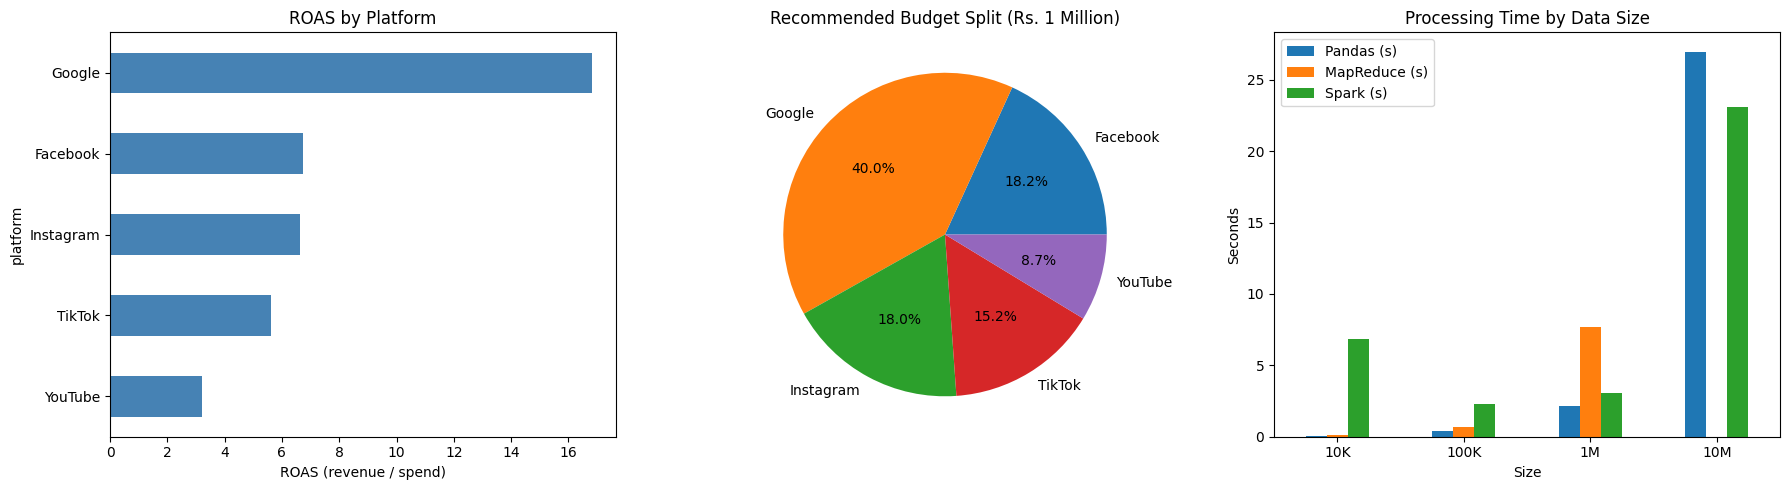

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

perf["ROAS"].sort_values().plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("ROAS by Platform")
axes[0].set_xlabel("ROAS (revenue / spend)")

perf["Budget %"].plot(kind="pie", ax=axes[1], autopct="%1.1f%%", ylabel="")
axes[1].set_title("Recommended Budget Split (Rs. 1 Million)")

timing.set_index("Size")[["Pandas (s)", "MapReduce (s)", "Spark (s)"]].plot(kind="bar", ax=axes[2])
axes[2].set_title("Processing Time by Data Size")
axes[2].set_ylabel("Seconds")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig("charts.png", dpi=150)
plt.show()

## Conclusion

- **Chhota data (10K, 100K):** Pandas sab se tez, kyunke Spark ka job startup overhead asal kaam se zyada hota hai.
- **Barhta data:** Pandas ka time tezi se barhta hai, Spark ka kam. 10M par Spark Pandas se aage nikal gaya (table dekho), kyunke wo data ko parallel partitions mein cores par baant deta hai.
- **MapReduce:** row-by-row Python loop ki wajah se sab se sust, isliye 10M par nahi chalaya.
- **Budget engine:** ROAS ke hisaab se Rs. 1 million ka split nikala, har platform par 5% se 40% ki limit ke saath taake risk ek jagah na ho.

**Limitations:** Data simulated hai. Sab kuch ek laptop (8 GB RAM, 4 cores) par local mode mein chala; asli cluster par Spark ka faida zyada hota. MapReduce Hadoop ki jagah Python functions se implement kiya gaya.

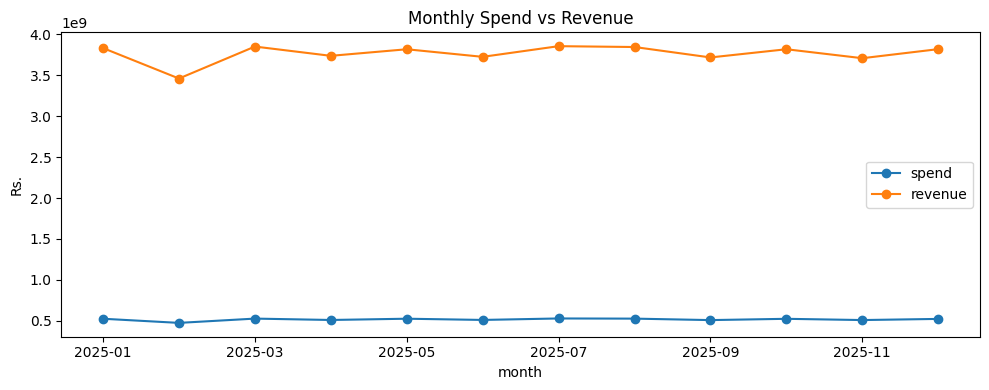

In [12]:
df_1m_m["month"] = df_1m_m["date"].dt.to_period("M").astype(str)
monthly = df_1m_m.groupby("month")[["spend", "revenue"]].sum()
monthly.plot(figsize=(10, 4), marker="o", title="Monthly Spend vs Revenue")
plt.ylabel("Rs.")
plt.tight_layout()
plt.savefig("monthly_trend.png", dpi=150)
plt.show()

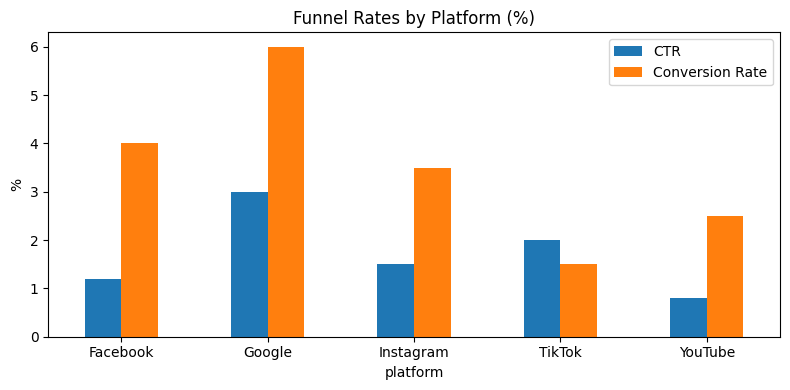

In [13]:
funnel = summary[["CTR"]].copy()
funnel["Conversion Rate"] = summary["conversions"] / summary["clicks"]
(funnel * 100).plot(kind="bar", figsize=(8, 4), title="Funnel Rates by Platform (%)")
plt.ylabel("%")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("funnel.png", dpi=150)
plt.show()